[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pabanib/Clases_clasificacion/blob/main/08_pca.ipynb#copy=true)


[![Open in Anaconda](https://static.anaconda.cloud/content/a22d04e8445b700f28937ab3231b8cded505d0395c63b7a269696722196d5415)](https://anaconda.com/api/nbserve/launch_notebook?nb_url=https%3A%2F%2Fanaconda.com%2Fapi%2Fprojects%2F6905e11d-e422-418c-ad09-bff2871f164e%2Ffiles%2F08_pca.ipynb%3Fversion%3Dd208ecd9-7a0f-4698-bde5-cafb52e61689)


# Análisis de componentes principales (PCA) y agrupamiento de clientes

Este notebook retoma la segmentación de clientes de **Online Retail** y responde tres preguntas:

1. ¿Cómo representar en dos dimensiones agrupamientos construidos con más variables?
2. ¿Cuánta variabilidad conserva esa representación y cómo se interpretan sus ejes?
3. ¿Qué cambia si primero reducimos la dimensión y después agrupamos?

Se utiliza el archivo `proceso_datos_online_retail.py` para procesar los datos que conserva el procesado del notebook anterior.


In [ ]:
import numpy as np
import pandas as pd
import proceso_datos_online_retail  as pdor
import  sklearn.cluster as cl
import matplotlib.pyplot as plt

In [ ]:
pdor.informacion()

In [ ]:
X = pdor.preprocesar()
X

In [ ]:
ventas = pdor.procesos_generales()
ventas.head()

# ¿Podemos visualizar mejor los clusters que armamos?

Cuando mostramos un agrupamiento en un gráfico de dos variables, vemos solo una parte de la información. En nuestro ejemplo, los grupos se formaron comparando once variables. Por eso, dos grupos pueden superponerse en un gráfico y diferenciarse en variables que no estamos mostrando.

El análisis de componentes principales (PCA en inglés o ACP en castellano) permite resumir esas variables en unos pocos componentes y representarlos en un gráfico.

En esta clase vamos a seguir este recorrido: visualizar los grupos que ya armamos, entender qué resume PCA, medir cuánta variabilidad conserva y usarlo antes de agrupar. **Duración orientativa: 25–30 minutos.**


In [ ]:


n_grupos = 5

aglo1 =  cl.AgglomerativeClustering(n_clusters = n_grupos,  metric = 'euclidean', linkage = 'ward')
km4 = cl.KMeans(n_clusters = n_grupos, init = "k-means++", n_init = 1, random_state = 5464)

aglo1.fit(X)
km4.fit(X)

In [ ]:
def graficar(v, df = ventas, x = 'cant_prom_operacion', y = 'gasto_prom_operacion'):
  fig, ax = plt.subplots( figsize = (10,5))
  colores = []
  for i in v.labels_:
    if i == 0:
      colores.append('blue')
    elif i == 1:
      colores.append('green')
    elif i == 2:
      colores.append('red')
    elif i == 3:
      colores.append('orange')
    else:
      colores.append('yellow')

  df.plot(kind = 'scatter', x = x, y = y, c = colores, ax = ax, alpha = 0.6)
  ax.set_title(type(v).__name__)
  if x == 'comp1':
    ax.set_xlabel(f'Componente 1 ({pca.explained_variance_ratio_[0]:.1%})')
    ax.set_ylabel(f'Componente 2 ({pca.explained_variance_ratio_[1]:.1%})')
  plt.tight_layout()
  plt.show()


graficar(aglo1)


In [ ]:
graficar(km4)

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components = 2)


In [ ]:
rdo = pca.fit_transform(X)
rdo = pd.DataFrame(rdo, columns=['comp1','comp2'])

graficar(aglo1, df = rdo, x = 'comp1', y = 'comp2')

In [ ]:
graficar(km4, df = rdo, x = 'comp1', y = 'comp2')

## ¿Qué es el análisis de componentes principales?

PCA es una técnica de reducción de la dimensión: construye nuevas variables, llamadas **componentes principales**, combinando las variables que ya tenemos.

El primer componente recoge la mayor variabilidad posible de los datos. El segundo recoge la mayor parte posible de la variabilidad restante y es perpendicular al primero. En la imagen de abajo, esas direcciones se representan con la línea verde y la línea azul punteada.

Podemos continuar obteniendo componentes, pero para reducir la dimensión nos quedamos con los primeros. **Cuánta información conservamos debe medirse:** no siempre alcanza con dos componentes.

PCA es sensible a las escalas. En este ejemplo, el módulo de preparación ya estandariza las variables numéricas y codifica las categóricas. PCA no estandariza automáticamente lo que recibe.


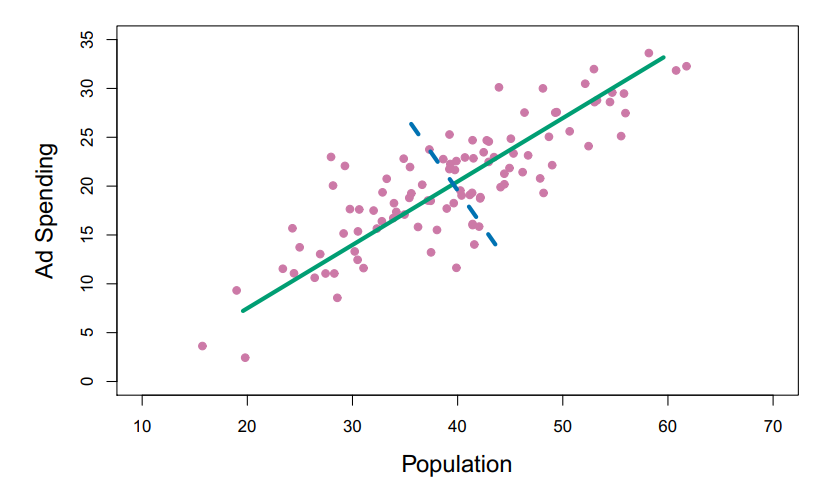

En el ejemplo de ventas online, ahora mostramos dos componentes que resumen las once variables utilizadas para formar los grupos. **Hasta acá los grupos no cambiaron: solo cambió la forma de representarlos.**

Los componentes no son directamente “gasto” o “cantidad”: combinan varias características. Por eso, sus ejes son menos intuitivos que los de las variables originales.

Una separación visual más clara no demuestra por sí sola que el agrupamiento sea mejor. Para interpretar este plano, primero veremos qué porcentaje de la variabilidad total conserva.


In [ ]:
rdo

### ¿Cuánta variabilidad conservamos?

La **varianza explicada** indica qué porcentaje de la variabilidad recoge cada componente. La **acumulada** suma esos porcentajes: permite decidir cuántos componentes conservar. Ajustamos un PCA con todos los componentes únicamente para obtener esta tabla; el PCA de dos componentes anterior queda igual.


In [ ]:
pca_total = PCA()
pca_total.fit(X)

variabilidad = pd.DataFrame({
    'Componente': np.arange(1, len(pca_total.explained_variance_ratio_) + 1),
    'Variabilidad explicada (%)': pca_total.explained_variance_ratio_ * 100,
    'Variabilidad acumulada (%)': np.cumsum(pca_total.explained_variance_ratio_) * 100
})
variabilidad.round(2)


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(variabilidad['Componente'], variabilidad['Variabilidad explicada (%)'])
ax[0].set(title='Variabilidad por componente', xlabel='Componente', ylabel='Porcentaje')
ax[1].plot(variabilidad['Componente'], variabilidad['Variabilidad acumulada (%)'], marker='o')
ax[1].axhline(90, color='red', linestyle='--', label='90 %')
ax[1].set(title='Variabilidad acumulada', xlabel='Cantidad de componentes', ylabel='Porcentaje', ylim=(0, 105))
ax[1].legend()
plt.tight_layout()
plt.show()

print(f'Con dos componentes conservamos {variabilidad.iloc[1, 2]:.2f}% de la variabilidad.')
n_90 = int(np.searchsorted(variabilidad['Variabilidad acumulada (%)'], 90) + 1)
print(f'Para conservar al menos el 90% necesitamos {n_90} componentes.')


En estos datos, dos componentes conservan aproximadamente el **79,72 %** de la variabilidad; el **20,28 %** restante no aparece en el plano. Para alcanzar el 90 % se necesitan **cuatro componentes**.

Dos componentes permiten dibujar un gráfico sencillo. Para un análisis que requiera conservar más información, podemos elegir más componentes, aunque ya no podamos mostrarlos todos en un solo plano. Ese porcentaje mide variabilidad conservada, no “porcentaje de aciertos” del agrupamiento.


## Utilizar PCA como preprocesado

Hasta ahora agrupamos con las once variables y usamos PCA para visualizar el resultado. También podemos invertir el orden: **primero reducir la dimensión y después agrupar sobre los componentes**.

Esto simplifica la representación, pero también descarta información y puede cambiar los grupos. No garantiza una mejor separación. Vamos a probar con dos componentes y comparar las siluetas.

Creamos nuevos modelos para conservar los agrupamientos anteriores y poder compararlos.


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

pipeline = make_pipeline(clone(pdor.preprocessor), PCA(4))


In [ ]:
X_ = pipeline.fit_transform(ventas)
X_

In [ ]:
aglo1_pca = clone(aglo1)
km4_pca = clone(km4)

aglo1_pca.fit(X_)
km4_pca.fit(X_)


In [ ]:
graficar(aglo1_pca)


In [ ]:
graficar(aglo1_pca, df = pd.DataFrame(X_[:,:2], columns = ['comp1','comp2']), x = 'comp1', y = 'comp2')


In [ ]:
graficar(km4_pca)


In [ ]:
graficar(km4_pca, df = pd.DataFrame(X_[:,:2], columns = ['comp1','comp2']), x = 'comp1', y = 'comp2')


### Comparar las siluetas

Recordemos: una silueta más cercana a 1 indica grupos más compactos y separados; cerca de 0, superposición; los valores negativos indican posibles asignaciones poco favorables.

Primero evaluamos los grupos nuevos en dos componentes. Luego comparamos los grupos anteriores y los nuevos **usando las once variables en ambos casos**. Una silueta mayor en el plano no demuestra una mejora en el espacio original: cambiaron las distancias utilizadas para medirla.


In [ ]:
from sklearn.metrics import silhouette_score, silhouette_samples

# Grupos formados con PCA, evaluados en el plano de dos componentes.
siluetas_plano = pd.Series({
    'Aglomerativo con PCA': silhouette_score(X_, aglo1_pca.labels_),
    'K-means con PCA': silhouette_score(X_, km4_pca.labels_)
}, name='Silueta en dos componentes')
siluetas_plano.to_frame().round(3)


In [ ]:
# Para comparar antes y después, evaluamos todos los grupos en el mismo X.
comparacion = pd.DataFrame({
    'Agrupar sin PCA': [silhouette_score(X, aglo1.labels_),
                       silhouette_score(X, km4.labels_)],
    'Agrupar con PCA': [silhouette_score(X, aglo1_pca.labels_),
                       silhouette_score(X, km4_pca.labels_)]
}, index=['Aglomerativo', 'K-means'])
comparacion.index.name = 'Silueta evaluada en las once variables'
comparacion.round(3)


In [ ]:
#importamos el mapa de colores
from matplotlib import cm

#Creamos una función que realiza el gráfico de siluetas
def graficoSiluetas(X, met):
  plt.figure(figsize=(8, 5))
  labels = np.unique(met.labels_) # define los niveles de los grupos
  n_clusters = labels.shape[0] #cantidad de grupos
  siluetas = silhouette_samples(X, met.labels_) #aplica el coef. de siluetas  uno a uno
  y_ax_lower, y_ax_upper = 0,0  # el lower define el piso en el que va empezar el grupo y el upper en dónde finaliza
  yticks = []
  for i, c in enumerate(labels):
    c_siluetas = siluetas[met.labels_ == c] #determina los valores del coef. para cada grupo
    c_siluetas.sort()
    y_ax_upper += len(c_siluetas)
    color = cm.jet(float(i)/n_clusters)
    plt.barh(range(y_ax_lower, y_ax_upper),
            c_siluetas,
            height = 1,
            edgecolor = 'none',
            color = color
            )
    yticks.append((y_ax_lower + y_ax_upper)/2)
    y_ax_lower += len(c_siluetas)

  silueta_prom = np.mean(siluetas)
  plt.axvline(silueta_prom, color = 'red', linestyle = "--")
  plt.yticks(yticks, labels)
  plt.title(f'Siluetas · {type(met).__name__} · {X.shape[1]} variables')
  plt.ylabel('Grupo')
  plt.xlabel('Coeficiente de siluetas')
  plt.show()


In [ ]:
graficoSiluetas(X, aglo1_pca)


In [ ]:
graficoSiluetas(X_, aglo1_pca)


In [ ]:
graficoSiluetas(X, km4_pca)


In [ ]:
graficoSiluetas(X_, km4_pca)


## Cierre

PCA nos permitió representar once variables con dos componentes, conservando cerca del 80 % de la variabilidad. Al usarlo solo para visualizar, las etiquetas se mantienen; al usarlo antes de agrupar, los grupos pueden cambiar.

En este ejemplo, al evaluar ambas alternativas en las once variables, la silueta del aglomerativo disminuye al agrupar con PCA y la de K-means cambia poco. Por lo tanto, no podemos afirmar que reducir a dos componentes mejore el agrupamiento. Su aporte más claro aquí es facilitar la visualización y resumir la información.
